# 32 — Candidate availability and physical compatibility ranking

Notebook 31 showed amplitude sensitivity but did not establish useful rankings. This diagnostic returns to the **original, unmodified notebook-29 queries** to separate absent candidates from ranking failures. It does not retrain or select a model.

## Diagnostic contract

A candidate must meet all three absolute-difference limits: central relief within `max(10 m, 25% of query relief)`, P90 slope within `3 degrees`, and median local elevation SD within `max(2 m, 25% of query local SD)`. These nominal limits are exploratory, not mission limits, independent labels or a complete morphology definition. The floors avoid unstable percentage differences near zero. Tight and wide sensitivity checks multiply every limit by 0.5 and 2.0. Rules are declared before this run; no best threshold is selected.

Limits are query-relative, so compatibility need not be symmetric. Relief, slope and local SD are correlated. Source resolution and uncertainty remain limitations; local SD does not measure rock abundance.

For each fixed query/pool, record whether any compatible candidate exists, the first compatible rank, top-one/top-five hits, and the smallest achievable maximum normalized feature error. A value at most 1 meets all limits. Compare CNN, untrained encoder and the existing physical baseline on identical pools. The physical baseline uses related descriptors, so this is an alignment diagnostic, not an independent relevance contest.

Keep lunar views, sampling variants, retrieval directions and all three development split cases separate. `heldout_queries` uses holdout queries and training candidates; `heldout_candidates` uses training queries and holdout candidates; `both_heldout` uses both holdouts. Atacama and Leibnitz are EDA-exposed development holdouts, not final tests. Final reserves remain closed.

In [7]:
import json
import sys
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "outline.md").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
from analysis_artifacts import rebase_links
from candidate_coverage import candidate_coverage
from inspection import check_input, file_hash, verify_run
from similarity_cnn import cosine_top_k
from terrain_dataset import FEATURES, validate_config
from terrain_learning import rank_candidates

SOURCE = ROOT / "data/processed/terrain_similarity_cnn/20261101T082707986851Z_5413e6"
DATASET = ROOT / "data/processed/terrain_learning_readiness/20261101T064233918547Z_4a05ac"
NOTEBOOK = ROOT / "notebooks/modeling/terrain_similarity/32_candidate_coverage_and_ranking.ipynb"
OUT = ROOT / "data/processed/analysis" / ("candidate-coverage-" + datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ"))
OUT.mkdir(parents=True, exist_ok=False)
expected = {**verify_run(SOURCE), **verify_run(DATASET)}
evidence = {str(p): file_hash(p) for p in [SOURCE / "provenance.json", DATASET / "provenance.json", NOTEBOOK,
    *(ROOT / "notebooks" / name for name in ["candidate_coverage.py", "inspection.py", "similarity_cnn.py",
                                            "terrain_dataset.py", "terrain_learning.py", "retrieval_analysis.py"])]}
CHECK_FEATURES = ["central_relief_m", "slope_p90_deg", "local_sd_median_m"]
THRESHOLDS = {"tight": .5, "nominal": 1., "wide": 2.}
GROUP = ["view", "sampling", "direction", "case", "threshold", "method"]
manifest = json.loads((DATASET / "provenance.json").read_text(encoding="utf-8"))
validate_config(manifest["config"])
assert manifest["config"]["patch_size_m"] == 960
patches = pd.read_csv(check_input(DATASET / "patches.csv", expected, evidence)).set_index("patch_id", verify_integrity=True)
roles = {(r["body"], r["region"]): r["fold"] for r in manifest["config"]["regions"]}
for item in patches[["body", "region", "role", "fold"]].drop_duplicates().to_dict("records"):
    assert item["role"] == "development" and roles.get((item["body"], item["region"])) == item["fold"]
assert np.isfinite(patches[FEATURES].to_numpy(dtype=float)).all()
assert (patches[CHECK_FEATURES].to_numpy(dtype=float) >= 0).all()
provenance = {"status": "running", "source": str(SOURCE.relative_to(ROOT)), "dataset": str(DATASET.relative_to(ROOT)),
    "threshold_multipliers": THRESHOLDS, "features": CHECK_FEATURES,
    "nominal_limits": ["max(10 m, .25 * query relief)", "3 degrees", "max(2 m, .25 * query local SD)"],
    "role": "development diagnostic; original queries; no training or independent relevance validation",
    "aggregation": "within-region means then equal-region means; conditional metrics exclude unavailable queries",
    "reserves_opened": False, "python": sys.version, "numpy": np.__version__, "pandas": pd.__version__, "torch": str(torch.__version__)}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")

907

In [8]:
rows = []
for view in ["full_context", "image_supported"]:
    queries = pd.read_csv(check_input(SOURCE / view / "evaluation_queries.csv", expected, evidence))
    assert queries["patch_id"].is_unique
    for sampling in ["region_balanced", "count_weighted"]:
        folder = SOURCE / view / sampling
        saved = pd.read_csv(check_input(folder / "retrieval.csv", expected, evidence))
        saved_top5 = {key: group.sort_values("rank")["candidate_id"].tolist()
                     for key, group in saved.groupby(["query_id", "case", "method"])}
        with np.load(check_input(folder / "embeddings.npz", expected, evidence), allow_pickle=False) as archive:
            ids = archive["patch_ids"].copy()
            embeddings = {method: archive[method].copy() for method in ["cnn", "random_encoder"]}
        assert len(set(ids)) == len(ids)
        bank = patches.loc[ids].copy()
        expected_ids = patches.index[patches["view"].isin(["natural_screen", view])]
        assert set(ids) == set(expected_ids)
        for field in ["body", "region", "fold"]:
            np.testing.assert_array_equal(bank.loc[queries["patch_id"], field], queries[field])
        descriptors = bank[FEATURES].to_numpy(dtype=float)
        physical = bank[CHECK_FEATURES].to_numpy(dtype=float)
        for query in queries.to_dict("records"):
            query_id = query["patch_id"]
            qi = bank.index.get_loc(query_id)
            assert isinstance(qi, (int, np.integer))
            other_body = "moon" if query["body"] == "earth" else "earth"
            cases = [("heldout_candidates", "holdout")] if query["fold"] == "train" else [
                ("heldout_queries", "train"), ("both_heldout", "holdout")]
            limits = np.array([max(10., .25 * physical[qi, 0]), 3., max(2., .25 * physical[qi, 2])])
            for case, fold in cases:
                pool = np.flatnonzero((bank["body"].to_numpy() == other_body) & (bank["fold"].to_numpy() == fold))
                candidate_ids = bank.index[pool].tolist()
                orders = {"physical": rank_candidates(descriptors[qi], descriptors[pool], candidate_ids, len(pool))[0]}
                orders.update({method: cosine_top_k(vectors[qi], vectors[pool], candidate_ids, len(pool))[0]
                               for method, vectors in embeddings.items()})
                for method, order in orders.items():
                    assert [candidate_ids[i] for i in order[:5]] == saved_top5[(query_id, case, method)]
                    relief_error = np.abs(physical[pool, 0] - physical[qi, 0])
                    for threshold, multiplier in THRESHOLDS.items():
                        stats = candidate_coverage(physical[qi], physical[pool], limits * multiplier, order)
                        first = stats["first_compatible_rank"]
                        rows.append({"view": view, "sampling": sampling, "direction": query["body"] + "_to_" + other_body,
                            "case": case, "threshold": threshold, "method": method, "query_id": query_id,
                            "query_region": query["region"], "candidate_count": len(pool), **stats,
                            "top1_candidate_id": candidate_ids[order[0]],
                            "first_compatible_id": candidate_ids[order[int(first) - 1]] if np.isfinite(first) else "",
                            "best_relief_error_m": float(relief_error.min()),
                            "top1_relief_error_m": float(relief_error[order[0]])})
        print(view, sampling, "complete; saved top-five rankings reproduced")
results = pd.DataFrame(rows)
assert not results.duplicated(GROUP + ["query_id"]).any()
assert len(results) == 4 * 448 * 3 * 3
identity = ["view", "direction", "case", "threshold", "query_id"]
assert (results.groupby(identity)["compatible_count"].nunique() == 1).all()
assert (results.groupby(identity)["candidate_count"].nunique() == 1).all()
results["available"] = results["compatible_count"] > 0
results["available_missed_top5"] = results["available"] & (results["top5_hit"] == 0)
results["unavailable"] = ~results["available"]
results["conditional_top5_hit"] = results["top5_hit"].where(results["available"])
results["conditional_top1_hit"] = results["top1_hit"].where(results["available"])
results["top1_relief_regret_m"] = results["top1_relief_error_m"] - results["best_relief_error_m"]
assert (results["top1_relief_regret_m"] >= -1e-8).all()
results.to_csv(OUT / "query_coverage.csv", index=False)

full_context region_balanced complete; saved top-five rankings reproduced
full_context count_weighted complete; saved top-five rankings reproduced
image_supported region_balanced complete; saved top-five rankings reproduced
image_supported count_weighted complete; saved top-five rankings reproduced


## Availability and ranking summaries

Every query belongs to exactly one state: no compatible candidate, compatible candidate available but absent from the top five, or a top-five hit. Unavailable queries are retained in coverage and unconditional hit rates. Conditional hit rates and first-compatible ranks are missing for those queries, not zero or an invented worst rank.

Regional tables expose query and available-query counts. Macro summaries give each query region equal weight; conditional means include only regions with available queries, and the contributing region count is reported. Small conditional denominators require caution. The two holdout directions each contain one query region. Reused queries and sampling variants are not independent trials; no significance claim is made.

In [9]:
metrics = ["available", "unavailable", "available_missed_top5", "top1_hit", "top5_hit",
           "conditional_top1_hit", "conditional_top5_hit", "compatible_fraction", "first_compatible_rank",
           "best_max_normalized_error", "top1_max_normalized_error", "best_relief_error_m", "top1_relief_regret_m"]
regional = results.groupby(GROUP + ["query_region"], as_index=False)[metrics].mean()
counts = results.groupby(GROUP + ["query_region"], as_index=False).agg(query_count=("query_id", "size"), available_query_count=("available", "sum"))
regional = regional.merge(counts, on=GROUP + ["query_region"], validate="one_to_one")
macro = regional.groupby(GROUP, as_index=False)[metrics].mean()
macro_counts = regional.groupby(GROUP, as_index=False).agg(
    query_region_count=("query_region", "size"), conditional_region_count=("conditional_top5_hit", "count"),
    query_count=("query_count", "sum"), available_query_count=("available_query_count", "sum"))
macro = macro.merge(macro_counts, on=GROUP, validate="one_to_one")
np.testing.assert_allclose(macro["unavailable"] + macro["available_missed_top5"] + macro["top5_hit"], 1.)
regional.to_csv(OUT / "regional_summary.csv", index=False)
macro.to_csv(OUT / "region_macro_summary.csv", index=False)
# One representative coverage row per query/pool/threshold; methods/samplers are not extra evidence.
results.drop_duplicates(identity)[identity + ["query_region", "candidate_count", "compatible_count", "available"]].to_csv(
    OUT / "candidate_availability.csv", index=False)
display(macro.loc[(macro["threshold"] == "nominal") & (macro["case"] == "both_heldout"),
    GROUP + ["query_count", "available_query_count", "conditional_top5_hit", "first_compatible_rank", "top1_relief_regret_m"]])
examples = results.loc[(results["threshold"] == "nominal") & (results["case"] == "both_heldout") &
                       (results["method"] == "cnn") & results["available_missed_top5"]].sort_values(
                           ["first_compatible_rank", "query_id"], ascending=[False, True])
examples.groupby(["view", "sampling", "direction"], sort=False).head(2).to_csv(OUT / "targeted_missed_examples.csv", index=False)

,view,sampling,direction,case,threshold,method,query_count,available_query_count,conditional_top5_hit,first_compatible_rank,top1_relief_regret_m
0,full_context,count_weighted,earth_to_moon,both_heldout,nominal,cnn,32,17,0.705882,9.235294,56.012267
1,full_context,count_weighted,earth_to_moon,both_heldout,nominal,physical,32,17,0.882353,2.705882,10.435442
2,full_context,count_weighted,earth_to_moon,both_heldout,nominal,random_encoder,32,17,0.823529,6.823529,15.594288
27,full_context,count_weighted,moon_to_earth,both_heldout,nominal,cnn,32,32,0.531250,27.500000,56.433982
28,full_context,count_weighted,moon_to_earth,both_heldout,nominal,physical,32,32,0.968750,2.250000,14.318472
29,full_context,count_weighted,moon_to_earth,both_heldout,nominal,random_encoder,32,32,0.968750,1.437500,18.486424
54,full_context,region_balanced,earth_to_moon,both_heldout,nominal,cnn,32,17,0.764706,14.058824,80.308123
55,full_context,region_balanced,earth_to_moon,both_heldout,nominal,physical,32,17,0.882353,2.705882,10.435442
56,full_context,region_balanced,earth_to_moon,both_heldout,nominal,random_encoder,32,17,0.823529,6.823529,15.594288
81,full_context,region_balanced,moon_to_earth,both_heldout,nominal,cnn,32,32,0.687500,13.718750,50.645127


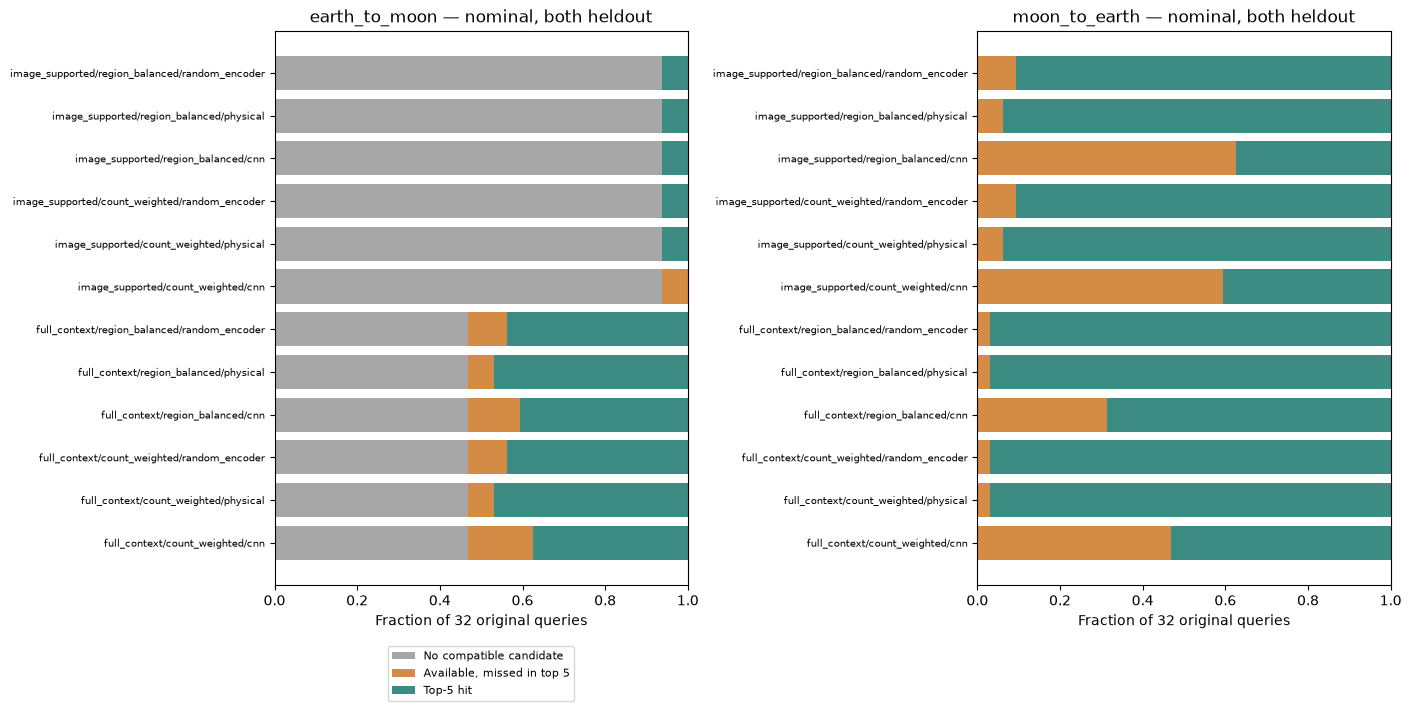

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
for ax, direction in zip(axes, ["earth_to_moon", "moon_to_earth"], strict=True):
    part = macro.loc[(macro["threshold"] == "nominal") & (macro["case"] == "both_heldout") &
                     (macro["direction"] == direction)].sort_values(["view", "sampling", "method"])
    labels = [f"{v}/{s}/{m}" for v, s, m in part[["view", "sampling", "method"]].itertuples(index=False, name=None)]
    left = np.zeros(len(part))
    for column, label, color in [("unavailable", "No compatible candidate", "#a7a7a7"),
                                  ("available_missed_top5", "Available, missed in top 5", "#d48b45"),
                                  ("top5_hit", "Top-5 hit", "#3c8c83")]:
        ax.barh(labels, part[column], left=left, label=label, color=color)
        left += part[column].to_numpy()
    ax.set(title=direction + " — nominal, both heldout", xlabel="Fraction of 32 original queries", xlim=(0, 1))
    ax.tick_params(axis="y", labelsize=7)
axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.1))
fig.savefig(OUT / "coverage_vs_ranking.png", dpi=130)
plt.show()
plt.close(fig)

## Observed result on the pinned development data

At nominal tolerances, all 32 lunar holdout queries have compatible Earth candidates in both views. Across the four variants, the CNN includes one in its top five for 37.5-68.8% of those queries; the physical baseline reaches 93.8-96.9% and the untrained encoder 90.6-96.9%. Thus a candidate shortage cannot explain all lunar-to-Earth physical mismatches.

Earth-to-Moon availability is much narrower: 17/32 queries in full context and 2/32 with image-supported lunar candidates. The latter becomes 0/32 under tight limits and 11/32 under wide limits, so the nominal conditional hit rate based on two queries is not a reliable basis for choosing a model. Coverage and ranking both need attention, and their importance depends on direction and view.

These results concern three measured descriptors under exploratory tolerances. They do not validate morphology relevance or mission suitability. More training is not yet justified by this diagnostic.

## Interpretation and next decision

Read threshold sensitivity and per-region denominators before assigning a cause. Absent candidates indicate a limitation of this fixed pool under these rules; they do not establish that no analog exists elsewhere. Available candidates ranked poorly indicate disagreement with this physical proxy, not necessarily poor shape relevance. Inspect the targeted missed examples as cases, not as a representative sample.

A physical compatibility filter followed by CNN ranking is a possible controlled follow-up, with explicit no-match handling. It must be evaluated against physical-only retrieval and independent morphology judgments before becoming the default. Do not loosen limits merely to improve hit rates, expand into final reserves, or train longer based on these diagnostics alone.

Reports and CSVs are saved under ignored `data/processed/analysis/`; notebook outputs remain cleared for Git.

In [11]:
notebook = nbformat.read(NOTEBOOK, as_version=4)
report = "\n\n".join(c.source for c in notebook.cells if c.cell_type == "markdown")
report = rebase_links(report, NOTEBOOK, OUT / "REPORT.md", {})
(OUT / "REPORT.md").write_text(report + "\n", encoding="utf-8")
provenance["inputs"] = evidence
provenance["outputs"] = {p.name: file_hash(p) for p in sorted(OUT.iterdir()) if p.is_file() and p.name != "provenance.json"}
provenance["status"] = "publishing"
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print("Complete:", OUT, "query/method/threshold rows:", len(results))


Complete: .\data\processed\analysis\candidate-coverage-20261102T143655601359Z query/method/threshold rows: 16128


## Save reusable data and disposable reports
Run this final cell after the displays. Later notebooks read only the data directory; reports can be deleted and regenerated.

In [12]:
import sys

sys.path.insert(0, str(ROOT / "notebooks"))
from analysis_artifacts import publish_analysis

REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable data:", OUT)
print("Disposable reports:", REPORT_OUT)

Reusable data: .\data\processed\analysis\candidate-coverage-20261102T143655601359Z
Disposable reports: .\reports\analysis\candidate-coverage-20261102T143655601359Z
